In [2]:

!pip install -q tensorflow-datasets


In [3]:

%pip install -q importlib_resources


In [4]:

%pip install -q datasets


In [5]:

from datasets import load_dataset

dataset = load_dataset(
    "geraldmc/plantvillage-full",
    revision="v0.1.0",
    split="train"
)

print(dataset)
print("Number of images:", len(dataset))
print("First image:", dataset[0]["image"].size)
print("First label:", dataset[0]["class_label"])


README.md:   0%|          | 0.00/549 [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  402MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  453MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/54304 [00:00<?, ? examples/s]

Dataset({
    features: ['image', 'class_label', 'class_idx', 'host', 'disease', 'split', 'leaf_id', 'leaf_grouped'],
    num_rows: 54304
})
Number of images: 54304
First image: (256, 256)
First label: Apple___Apple_scab


In [6]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Get the 38 class names directly from the dataset
class_names = sorted(set(dataset["class_label"]))

print("Number of classes:", len(class_names))
print("First 10 classes:", class_names[:10])

# Split into training (70%), validation (15%), and testing (15%)
dataset_split = dataset.train_test_split(
    test_size=0.30,
    seed=42
)

temp_split = dataset_split["test"].train_test_split(
    test_size=0.50,
    seed=42
)

train_data = dataset_split["train"]
val_data = temp_split["train"]
test_data = temp_split["test"]

print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Testing images:", len(test_data))


Number of classes: 38
First 10 classes: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight']
Training images: 38012
Validation images: 8146
Testing images: 8146


In [7]:
import tensorflow as tf
import numpy as np

IMG_SIZE = 128
BATCH_SIZE = 32

class_to_idx = {name: i for i, name in enumerate(class_names)}

def make_tf_dataset(hf_data, shuffle=False):
    def generator():
        for row in hf_data:
            image = row["image"].convert("RGB")
            image = image.resize((IMG_SIZE, IMG_SIZE))

            image = np.asarray(image, dtype=np.float32) / 255.0
            label = class_to_idx[row["class_label"]]

            yield image, np.int32(label)

    output_signature = (
        tf.TensorSpec(
            shape=(IMG_SIZE, IMG_SIZE, 3),
            dtype=tf.float32
        ),
        tf.TensorSpec(shape=(), dtype=tf.int32)
    )

    ds = tf.data.Dataset.from_generator(
        generator,
        output_signature=output_signature
    )

    if shuffle:
        ds = ds.shuffle(2000, seed=42)

    return ds.batch(BATCH_SIZE).prefetch(1)

train_ds = make_tf_dataset(train_data, shuffle=True)
val_ds = make_tf_dataset(val_data)
test_ds = make_tf_dataset(test_data)

print("Datasets created successfully!")


Datasets created successfully!


In [8]:

# Check that the datasets are ready
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

print("Number of classes:", len(class_names))


Image batch shape: (32, 128, 128, 3)
Label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Number of classes: 38


In [9]:

from tensorflow.keras import layers, models

# Data augmentation to help the model generalize
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])

# Build the CNN
model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    data_augmentation,

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    layers.Dense(len(class_names), activation="softmax")
])

# Configure the model for training
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 38)             │         4,902 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 114,662 (447.90 KB)

 Trainable params: 114,662 (447.90 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:

# Import required callbacks
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Save the best model and stop training if validation stops improving
callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        "best_plant_disease.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

# Train the CNN
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=12,
    callbacks=callbacks
)



Epoch 1/12
   1188/Unknown 116s 87ms/step - accuracy: 0.2266 - loss: 2.9124

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


1188/1188 ━━━━━━━━━━━━━━━━━━━━ 138s 105ms/step - accuracy: 0.3235 - loss: 2.4645 - val_accuracy: 0.4996 - val_loss: 1.6949
Epoch 2/12
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 130s 105ms/step - accuracy: 0.5656 - loss: 1.4588 - val_accuracy: 0.6337 - val_loss: 1.1735
Epoch 3/12
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 131s 106ms/step - accuracy: 0.6686 - loss: 1.1008 - val_accuracy: 0.7353 - val_loss: 0.8551
Epoch 4/12
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 131s 107ms/step - accuracy: 0.7148 - loss: 0.9328 - val_accuracy: 0.7072 - val_loss: 0.9243
Epoch 5/12
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 132s 107ms/step - accuracy: 0.7451 - loss: 0.8182 - val_accuracy: 0.7271 - val_loss: 0.8987
Epoch 6/12
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 131s 106ms/step - accuracy: 0.7707 - loss: 0.7370 - val_accuracy: 0.7310 - val_loss: 0.8501
Epoch 7/12
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 132s 107ms/step - accuracy: 0.7868 - loss: 0.6721 - val_accuracy: 0.7421 - val_loss: 0.8185
Epoch 8/12
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 143s 108ms/step - accuracy: 0.8

In [11]:

import math

# Load the best saved checkpoint
model = tf.keras.models.load_model("best_plant_disease.keras")

# Evaluate on unseen test images
test_steps = math.ceil(len(test_data) / BATCH_SIZE)

test_loss, test_accuracy = model.evaluate(
    test_ds,
    steps=test_steps,
    verbose=1
)

print(f"\nTest Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")


255/255 ━━━━━━━━━━━━━━━━━━━━ 25s 95ms/step - accuracy: 0.8758 - loss: 0.3896

Test Accuracy: 87.58%
Test Loss: 0.3896


In [12]:

import json

# Save the model for our web application
model.save("plant_disease_model.keras")

# Save class names in the exact prediction order
with open("class_names.json", "w") as f:
    json.dump(class_names, f, indent=4)

print("Model and class names saved successfully!")


Model and class names saved successfully!


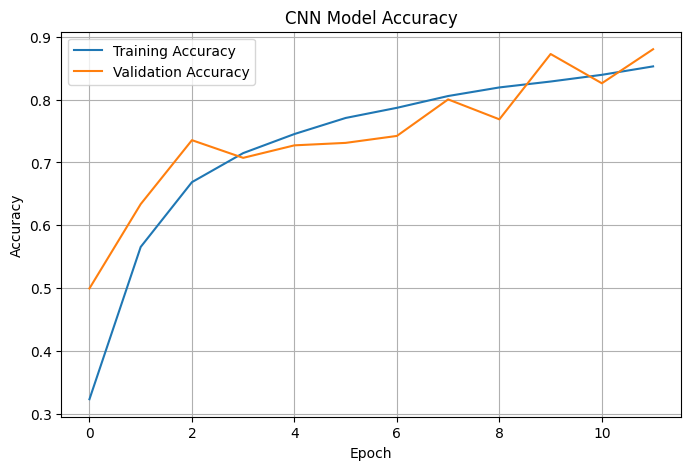

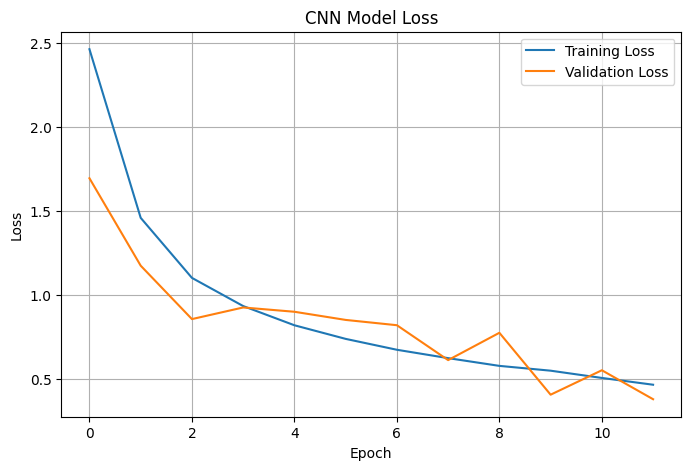

In [13]:

import matplotlib.pyplot as plt

# Plot training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.savefig("accuracy_plot.png", dpi=300, bbox_inches="tight")
plt.show()

# Plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.savefig("loss_plot.png", dpi=300, bbox_inches="tight")
plt.show()


In [14]:

import json

# Save the trained model
model.save("plant_disease_model.keras")

# Save the class labels in prediction order
with open("class_names.json", "w") as f:
    json.dump(class_names, f, indent=4)

print("Model saved successfully!")
print("Class names saved successfully!")


Model saved successfully!
Class names saved successfully!


In [15]:

import os

files_to_check = [
    "plant_disease_model.keras",
    "class_names.json",
    "accuracy_plot.png",
    "loss_plot.png"
]

for file in files_to_check:
    if os.path.exists(file):
        size_mb = os.path.getsize(file) / (1024 * 1024)
        print(f"{file}: {size_mb:.2f} MB")
    else:
        print(f"{file}: NOT FOUND")


plant_disease_model.keras: 1.37 MB
class_names.json: 0.00 MB
accuracy_plot.png: 0.13 MB
loss_plot.png: 0.11 MB
